In [ ]:
!pip install -q datasets huggingface_hub

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

In [ ]:
import os
import zipfile
from huggingface_hub import hf_hub_download
from datasets import load_dataset

# Repository information
repo_id = "serag-ai/Synthetic-Ophthalmology-Images"
zip_files = ["CNV.zip", "DME.zip", "Drusen.zip", "Normal.zip"]
local_dir = "Synthetic-Ophthalmology-Images-Data"
extract_dir = "unzipped_images"

os.makedirs(local_dir, exist_ok=True)
os.makedirs(extract_dir, exist_ok=True)

# 1. Download ZIP files
print("Downloading ZIP files...")
for zip_file in zip_files:
    dest_path = os.path.join(local_dir, zip_file)
    if not os.path.exists(dest_path):
        hf_hub_download(
            repo_id=repo_id,
            filename=zip_file,
            repo_type="dataset",
            local_dir=local_dir
        )

# 2. Extract each ZIP to its own class folder
print("Extracting files...")
for zip_file in zip_files:
    class_name = zip_file.replace(".zip", "")
    class_dir = os.path.join(extract_dir, class_name)
    zip_path = os.path.join(local_dir, zip_file)

    if not os.path.exists(class_dir):
        os.makedirs(class_dir, exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(class_dir)

# 3. Load the clean unzipped folder as a dataset
print("Loading dataset...")
synthetic_ds = load_dataset(
    "imagefolder",
    data_dir=extract_dir
)

print(synthetic_ds)

Extracting files...
Loading dataset...


Resolving data files:   0%|          | 0/26848 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 26848
    })
})


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'kermany2018' dataset.
Path to dataset files: /kaggle/input/kermany2018


In [ ]:
print(synthetic_ds)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 26848
    })
})


In [ ]:
print(synthetic_ds["train"].features)

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'Drusen', 'Normal'])}


dict_keys(['image', 'label'])


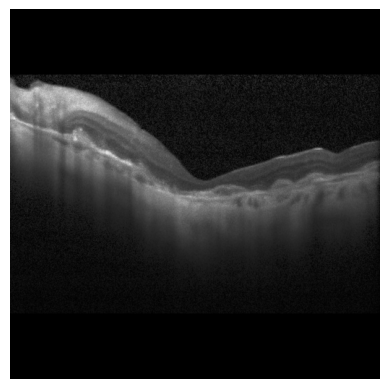

In [ ]:
sample = synthetic_ds["train"][0]

print(sample.keys())
sample["image"]
plt.imshow(sample["image"])
plt.axis("off")
plt.show()

In [ ]:
#select 500 from each class in syn
import random

dataset = synthetic_ds["train"]

selected_images = []

for class_id in range(4):

    class_data = dataset.filter(
        lambda x: x["label"] == class_id
    )

    class_data = class_data.shuffle(seed=42)

    class_data = class_data.select(
        range(500)
    )

    selected_images.append(class_data)

print("Done!")

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Done!


In [ ]:
#combine all as new syn
from datasets import concatenate_datasets

synthetic_2000 = concatenate_datasets(
    selected_images
)

print(len(synthetic_2000))

2000


In [ ]:
#checking
from collections import Counter

print(
    Counter(synthetic_2000["label"])
)

Counter({0: 500, 1: 500, 2: 500, 3: 500})


In [ ]:
# Load the downloaded real dataset first
from datasets import load_dataset
import os
import kagglehub

# Ensure path is defined by downloading/locating the dataset
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

# The dataset has train/test subfolders; let's target the 'train' folder as our source
real_dataset_dir = os.path.join(path, "OCT2017 ", "train") if os.path.exists(os.path.join(path, "OCT2017 ")) else os.path.join(path, "train")

real_dataset = load_dataset(
    "imagefolder",
    data_dir=real_dataset_dir,
    split="train"
)

# select 500 from each real class
real_selected = []

for class_id in range(4):

    class_data = real_dataset.filter(
        lambda x: x["label"] == class_id
    )

    class_data = class_data.shuffle(seed=42)

    class_data = class_data.select(
        range(500)
    )

    real_selected.append(class_data)

Using Colab cache for faster access to the 'kermany2018' dataset.


Resolving data files:   0%|          | 0/83484 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/83484 [00:00<?, ? examples/s]

Filter:   0%|          | 0/83484 [00:00<?, ? examples/s]

Filter:   0%|          | 0/83484 [00:00<?, ? examples/s]

Filter:   0%|          | 0/83484 [00:00<?, ? examples/s]

In [ ]:
#combine
from datasets import concatenate_datasets

real_2000 = concatenate_datasets(
    real_selected
)

print(len(real_2000))

2000


In [ ]:
#checking
from collections import Counter

print(
    Counter(real_2000["label"])
)

Counter({0: 500, 1: 500, 2: 500, 3: 500})


In [ ]:
from collections import Counter
from datasets import load_dataset, concatenate_datasets
import os

# Ensure synthetic_2000 is defined in the current runtime context
if 'synthetic_2000' not in globals():
    extract_dir = "unzipped_images"
    if os.path.exists(extract_dir):
        synthetic_ds = load_dataset("imagefolder", data_dir=extract_dir)
        dataset = synthetic_ds["train"]

        # Recreate the balanced synthetic dataset
        selected_images = []
        for class_id in range(4):
            class_data = dataset.filter(lambda x: x["label"] == class_id)
            class_data = class_data.shuffle(seed=42)
            class_data = class_data.select(range(500))
            selected_images.append(class_data)

        synthetic_2000 = concatenate_datasets(selected_images)
    else:
        raise FileNotFoundError("Synthetic dataset images not found. Please run cell Q0Pl7xY0ROdZ first.")

print("Synthetic OCT:", len(synthetic_2000))
print("Real OCT:", len(real_2000))

print("\nSynthetic class distribution:")
for class_id, count in sorted(Counter(synthetic_2000["label"]).items()):
    name = synthetic_2000.features["label"].int2str(class_id)
    print(name, ":", count)

print("\nReal class distribution:")
for class_id, count in sorted(Counter(real_2000["label"]).items()):
    name = real_2000.features["label"].int2str(class_id)
    print(name, ":", count)

Synthetic OCT: 2000
Real OCT: 2000

Synthetic class distribution:
CNV : 500
DME : 500
Drusen : 500
Normal : 500

Real class distribution:
CNV : 500
DME : 500
DRUSEN : 500
NORMAL : 500


In [ ]:
#ignore cell
import os
import zipfile
from huggingface_hub import hf_hub_download
from datasets import load_dataset, concatenate_datasets

# Redownload and extract synthetic data if missing
repo_id = "serag-ai/Synthetic-Ophthalmology-Images"
zip_files = ["CNV.zip", "DME.zip", "Drusen.zip", "Normal.zip"]
local_dir = "Synthetic-Ophthalmology-Images-Data"
extract_dir = "unzipped_images"

os.makedirs(local_dir, exist_ok=True)
os.makedirs(extract_dir, exist_ok=True)

print("Downloading and extracting files...")
for zip_file in zip_files:
    dest_path = os.path.join(local_dir, zip_file)
    if not os.path.exists(dest_path):
        hf_hub_download(
            repo_id=repo_id,
            filename=zip_file,
            repo_type="dataset",
            local_dir=local_dir
        )

    class_name = zip_file.replace(".zip", "")
    class_dir = os.path.join(extract_dir, class_name)
    if not os.path.exists(class_dir):
        os.makedirs(class_dir, exist_ok=True)
        with zipfile.ZipFile(dest_path, 'r') as zip_ref:
            zip_ref.extractall(class_dir)

# Now load, filter, and recreate synthetic_2000
synthetic_ds = load_dataset("imagefolder", data_dir=extract_dir)
dataset = synthetic_ds["train"]

selected_images = []
for class_id in range(4):
    class_data = dataset.filter(lambda x: x["label"] == class_id)
    class_data = class_data.shuffle(seed=42)
    class_data = class_data.select(range(500))
    selected_images.append(class_data)

synthetic_2000 = concatenate_datasets(selected_images)
print("Synthetic dataset reconstructed successfully with size:", len(synthetic_2000))

CNV.zip: reconstructing file:   0%|          |  0.00B / 1.75GB            

CNV.zip: downloading bytes:           |  0.00B            

DME.zip: reconstructing file:   0%|          |  0.00B / 2.02GB            

DME.zip: downloading bytes:           |  0.00B            

Drusen.zip: reconstructing file:   0%|          |  0.00B / 1.73GB            

Drusen.zip: downloading bytes:           |  0.00B            

... (5 outputs left out)

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Filter:   0%|          | 0/26848 [00:00<?, ? examples/s]

Synthetic dataset reconstructed successfully with size: 2000


Real images: 2000
Synthetic images: 2000


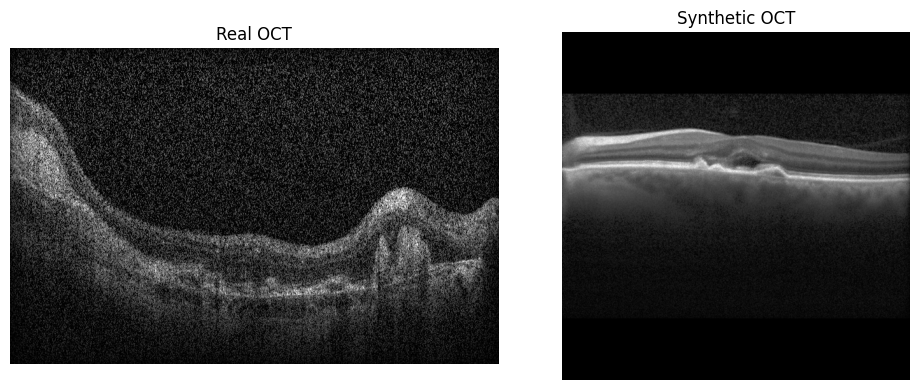

In [ ]:
#preprocessing
print("Real images:", len(real_2000))
print("Synthetic images:", len(synthetic_2000))

# Preview one image from each dataset
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(real_2000[0]["image"], cmap="gray")
axes[0].set_title("Real OCT")

axes[1].imshow(synthetic_2000[0]["image"], cmap="gray")
axes[1].set_title("Synthetic OCT")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Real OCT images: 2000
Synthetic OCT images: 2000

Real dataset columns: ['image', 'label']
Synthetic dataset columns: ['image', 'label']


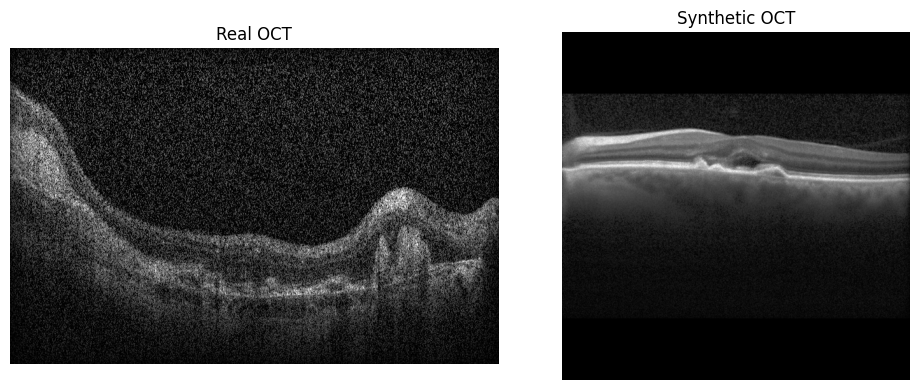

In [ ]:
#checking datasbases
import matplotlib.pyplot as plt

# 1. Check dataset sizes
print("Real OCT images:", len(real_2000))
print("Synthetic OCT images:", len(synthetic_2000))

# 2. Check dataset structure
print("\nReal dataset columns:", real_2000.column_names)
print("Synthetic dataset columns:", synthetic_2000.column_names)

# 3. Display one image from each dataset
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(real_2000[0]["image"], cmap="gray")
axes[0].set_title("Real OCT")
axes[0].axis("off")

axes[1].imshow(synthetic_2000[0]["image"], cmap="gray")
axes[1].set_title("Synthetic OCT")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
from PIL import Image
from tqdm.auto import tqdm

IMG_SIZE = (224, 224)

def preprocess_image(image):
    # Convert to grayscale
    image = image.convert("L")

    # Resize all images to the same size
    image = image.resize(IMG_SIZE)

    # Convert pixels to numbers between 0 and 1
    image = np.asarray(image, dtype=np.float32) / 255.0

    return image

# Preprocess real OCT images
real_images = np.stack([
    preprocess_image(item["image"])
    for item in tqdm(real_2000, desc="Real OCT")
])

# Preprocess synthetic OCT images
synthetic_images = np.stack([
    preprocess_image(item["image"])
    for item in tqdm(synthetic_2000, desc="Synthetic OCT")
])

print("Real images shape:", real_images.shape)
print("Synthetic images shape:", synthetic_images.shape)
print("Real pixel range:", real_images.min(), "to", real_images.max())
print("Synthetic pixel range:", synthetic_images.min(), "to", synthetic_images.max())

Real OCT:   0%|          | 0/2000 [00:00<?, ?it/s]

Synthetic OCT:   0%|          | 0/2000 [00:00<?, ?it/s]

Real images shape: (2000, 224, 224)
Synthetic images shape: (2000, 224, 224)
Real pixel range: 0.0 to 1.0
Synthetic pixel range: 0.0 to 1.0


In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import entropy, skew, kurtosis
from skimage.feature import graycomatrix, graycoprops
from tqdm.auto import tqdm

def extract_statistical_features(images, dataset_name):
    results = []

    for img in tqdm(images, desc=f"Analyzing {dataset_name}"):
        # Convert normalized pixels to 8-bit grayscale
        img_uint8 = (img * 255).astype(np.uint8)

        # Histogram-based entropy
        hist = np.histogram(
            img_uint8, bins=256, range=(0, 256)
        )[0]
        probabilities = hist / hist.sum()
        image_entropy = entropy(probabilities, base=2)

        # Contrast from gray-level co-occurrence matrix
        glcm = graycomatrix(
            img_uint8,
            distances=[1],
            angles=[0],
            levels=256,
            symmetric=True,
            normed=True
        )
        contrast = graycoprops(glcm, "contrast")[0, 0]

        # Statistical features
        results.append({
            "mean_intensity": np.mean(img),
            "std_intensity": np.std(img),
            "entropy": image_entropy,
            "contrast": contrast,
            "skewness": skew(img.ravel()),
            "kurtosis": kurtosis(img.ravel())
        })

    df = pd.DataFrame(results)
    df["dataset"] = dataset_name
    return df

# Extract features from both datasets
real_stats = extract_statistical_features(real_images, "Real")
synthetic_stats = extract_statistical_features(
    synthetic_images, "Synthetic"
)

# Combine into one table
stats_df = pd.concat(
    [real_stats, synthetic_stats],
    ignore_index=True
)

print("Feature table shape:", stats_df.shape)
display(stats_df.head())

Analyzing Real:   0%|          | 0/2000 [00:00<?, ?it/s]

Analyzing Synthetic:   0%|          | 0/2000 [00:00<?, ?it/s]

Feature table shape: (4000, 7)


,mean_intensity,std_intensity,entropy,contrast,skewness,kurtosis,dataset
0,0.152280,0.115783,6.506506,274.189142,1.630086,2.854406,Real
1,0.177978,0.195690,6.660597,97.409413,2.210453,5.293287,Real
2,0.235951,0.223860,6.993254,204.641015,1.930749,3.734056,Real
3,0.337865,0.295623,7.049562,105.581378,1.067621,0.035633,Real
4,0.299226,0.284968,6.820921,84.521461,1.474391,1.137815,Real


In [ ]:
#Level 1: Statistical Analysis
import pandas as pd

feature_cols = [
    "mean_intensity",
    "std_intensity",
    "entropy",
    "contrast",
    "skewness",
    "kurtosis"
]

summary = stats_df.groupby("dataset")[feature_cols].agg(
    ["mean", "std", "median"]
)

display(summary.round(4))

mean_intensity                 std_intensity                  \
                    mean     std  median          mean     std  median   
dataset                                                                  
Real              0.1923  0.0725  0.1758        0.1946  0.0693  0.1741   
Synthetic         0.2349  0.1019  0.2245        0.2036  0.0635  0.1933   

          entropy                  contrast                     skewness  \
             mean     std  median      mean       std    median     mean   
dataset                                                                    
Real       6.4557  0.3039  6.4844  129.6246   78.3409  105.6610   2.0753   
Synthetic  6.4310  0.8882  6.6852  144.5243  122.7360  116.8849   1.8919   

                          kurtosis                  
              std  median     mean     std  median  
dataset                                             
Real       0.5109  2.0924   4.7276  2.9702  4.6138  
Synthetic  0.6692  1.8873   4.1539  3.7333  3.6282

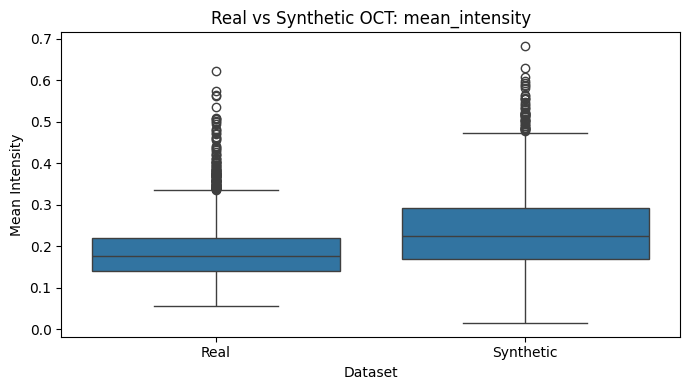

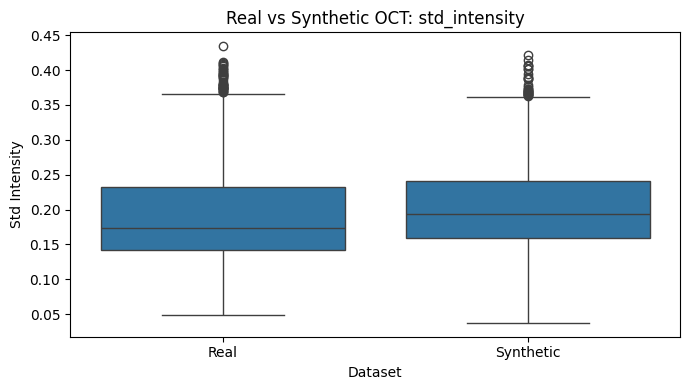

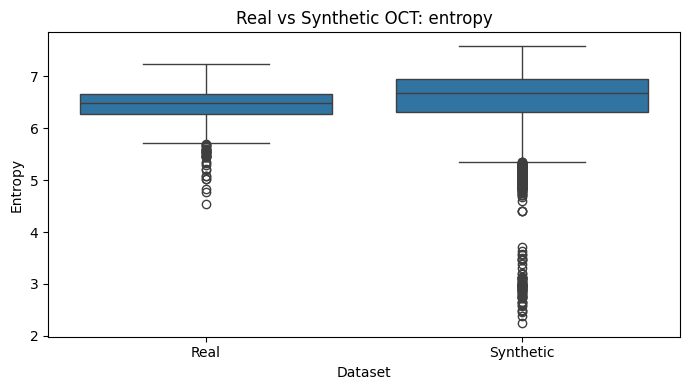

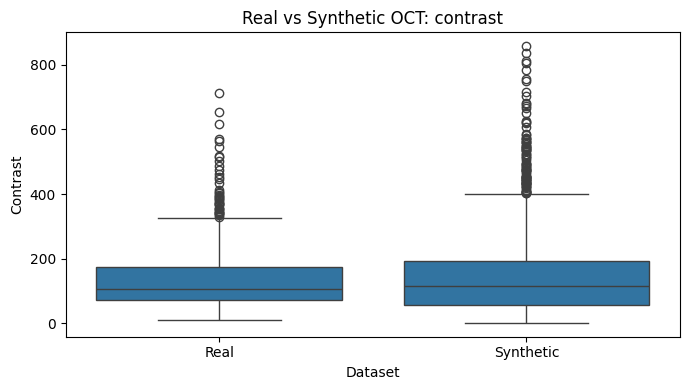

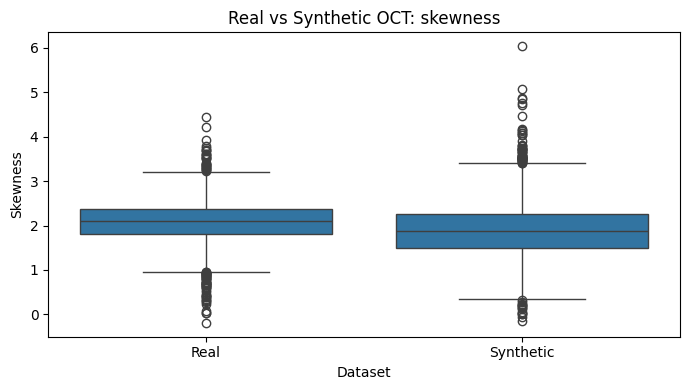

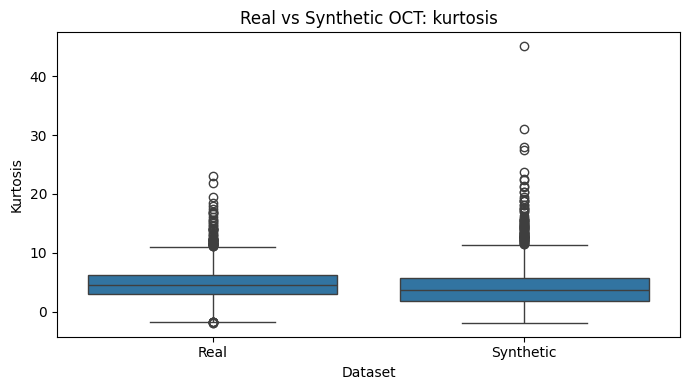

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

for feature in feature_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=stats_df,
        x="dataset",
        y=feature
    )

    plt.title(f"Real vs Synthetic OCT: {feature}")
    plt.xlabel("Dataset")
    plt.ylabel(feature.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

In [ ]:

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

results = []

for feature in feature_cols:
    real_values = stats_df.loc[
        stats_df["dataset"] == "Real", feature
    ].dropna()

    synthetic_values = stats_df.loc[
        stats_df["dataset"] == "Synthetic", feature
    ].dropna()

    statistic, p_value = mannwhitneyu(
        real_values,
        synthetic_values,
        alternative="two-sided"
    )

    results.append({
        "Feature": feature,
        "Real median": real_values.median(),
        "Synthetic median": synthetic_values.median(),
        "U statistic": statistic,
        "p-value": p_value
    })

results_df = pd.DataFrame(results)

# Correct for testing six features
results_df["adjusted_p_value"] = multipletests(
    results_df["p-value"],
    method="fdr_bh"
)[1]

results_df["Significant (adjusted p < 0.05)"] = (
    results_df["adjusted_p_value"] < 0.05
)

display(results_df.round(5))

,Feature,Real median,Synthetic median,U statistic,p-value,adjusted_p_value,Significant (adjusted p < 0.05)
0,mean_intensity,0.17576,0.22451,1410409.5,0.00000,0.00000,True
1,std_intensity,0.17411,0.19332,1740631.0,0.00000,0.00000,True
2,entropy,6.48442,6.68515,1493814.0,0.00000,0.00000,True
3,contrast,105.66098,116.88488,2023128.0,0.52654,0.52654,False
4,skewness,2.09242,1.88733,2430546.5,0.00000,0.00000,True
5,kurtosis,4.61379,3.62824,2339701.0,0.00000,0.00000,True


In [ ]:
#Level 2: Structural Analysis

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from scipy.ndimage import sobel

def extract_structural_features(images, dataset_name):
    results = []

    for img in tqdm(images, desc=f"Structural analysis: {dataset_name}"):
        # Calculate horizontal and vertical intensity gradients
        grad_x = sobel(img, axis=1)
        grad_y = sobel(img, axis=0)

        # Gradient magnitude measures how quickly intensity changes
        gradient_magnitude = np.sqrt(grad_x**2 + grad_y**2)

        # Edge strength and structural variation
        results.append({
            "mean_gradient": np.mean(gradient_magnitude),
            "std_gradient": np.std(gradient_magnitude),
            "median_gradient": np.median(gradient_magnitude),
            "strong_edge_fraction": np.mean(gradient_magnitude > 0.1)
        })

    df = pd.DataFrame(results)
    df["dataset"] = dataset_name
    return df

real_structural = extract_structural_features(real_images, "Real")
synthetic_structural = extract_structural_features(
    synthetic_images, "Synthetic"
)

structural_df = pd.concat(
    [real_structural, synthetic_structural],
    ignore_index=True
)

print("Structural feature table shape:", structural_df.shape)
display(structural_df.head())

Structural analysis: Real:   0%|          | 0/2000 [00:00<?, ?it/s]

Structural analysis: Synthetic:   0%|          | 0/2000 [00:00<?, ?it/s]

Structural feature table shape: (4000, 5)


,mean_gradient,std_gradient,median_gradient,strong_edge_fraction,dataset
0,0.264499,0.197694,0.218273,0.830537,Real
1,0.220555,0.381648,0.117647,0.581553,Real
2,0.292289,0.373921,0.214291,0.817403,Real
3,0.223562,0.354699,0.138759,0.644471,Real
4,0.222614,0.355431,0.142153,0.653360,Real


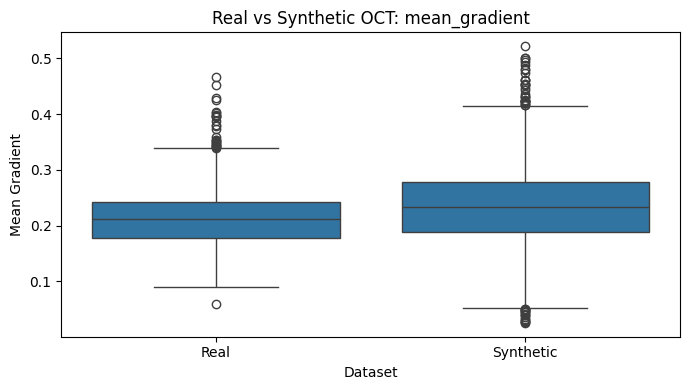

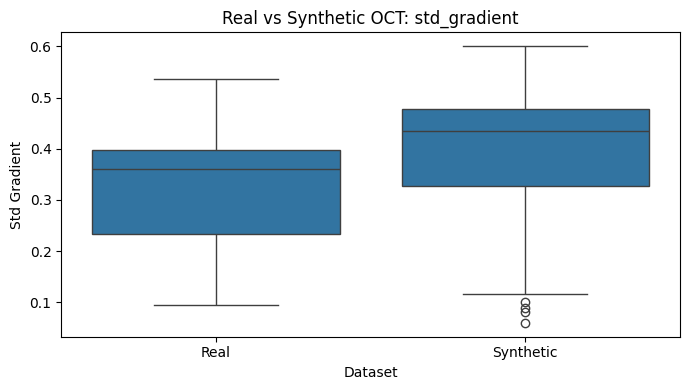

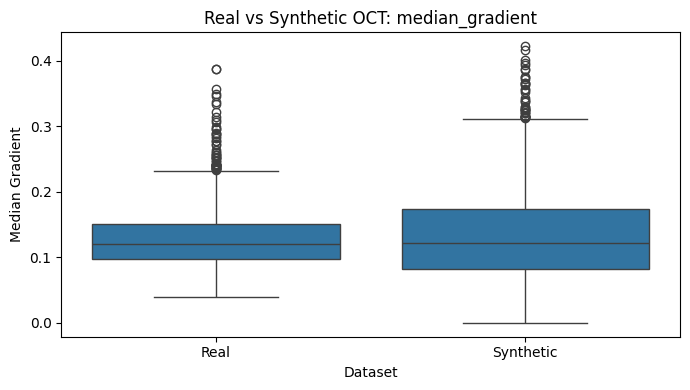

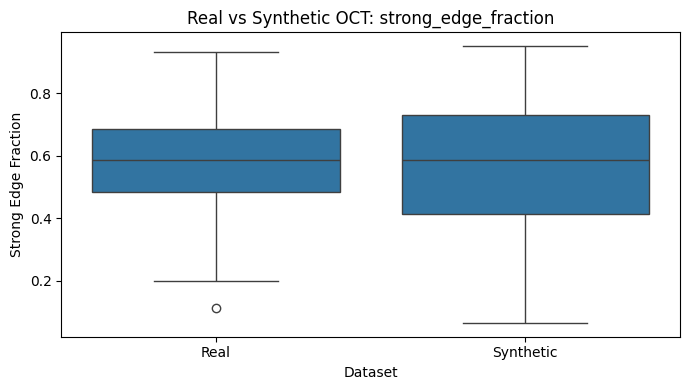

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

structural_features = [
    "mean_gradient",
    "std_gradient",
    "median_gradient",
    "strong_edge_fraction"
]

for feature in structural_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=structural_df, x="dataset", y=feature)
    plt.title(f"Real vs Synthetic OCT: {feature}")
    plt.xlabel("Dataset")
    plt.ylabel(feature.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

In [ ]:

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

structural_results = []

for feature in structural_features:
    real_values = structural_df.loc[
        structural_df["dataset"] == "Real", feature
    ].dropna()

    synthetic_values = structural_df.loc[
        structural_df["dataset"] == "Synthetic", feature
    ].dropna()

    statistic, p_value = mannwhitneyu(
        real_values,
        synthetic_values,
        alternative="two-sided"
    )

    structural_results.append({
        "Feature": feature,
        "Real median": real_values.median(),
        "Synthetic median": synthetic_values.median(),
        "U statistic": statistic,
        "p-value": p_value
    })

structural_results_df = pd.DataFrame(structural_results)

structural_results_df["adjusted_p_value"] = multipletests(
    structural_results_df["p-value"],
    method="fdr_bh"
)[1]

structural_results_df["Significant (adjusted p < 0.05)"] = (
    structural_results_df["adjusted_p_value"] < 0.05
)

display(structural_results_df.round(5))


,Feature,Real median,Synthetic median,U statistic,p-value,adjusted_p_value,Significant (adjusted p < 0.05)
0,mean_gradient,0.21142,0.23361,1612586.0,0.00000,0.00000,True
1,std_gradient,0.35990,0.43481,1218875.0,0.00000,0.00000,True
2,median_gradient,0.11998,0.12173,2027275.5,0.45514,0.45514,False
3,strong_edge_fraction,0.58717,0.58567,2055884.5,0.12595,0.16794,False


In [ ]:
#Deep feature analysis
import torch
import torchvision.models as models
from torchvision import transforms
from PIL import Image
import numpy as np
from tqdm.auto import tqdm

# Use GPU if Colab provides one
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load pretrained ResNet-18 weights
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Remove the final classification layer.
# The model will return a 512-dimensional feature vector.
model.fc = torch.nn.Identity()

model = model.to(device)
model.eval()

print("Pretrained ResNet-18 is ready.")

Using device: cuda
Pretrained ResNet-18 is ready.


In [ ]:

preprocess_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def prepare_resnet_image(img):
    # Convert normalized grayscale array back to an 8-bit image
    img_uint8 = (np.clip(img, 0, 1) * 255).astype(np.uint8)
    pil_img = Image.fromarray(img_uint8).convert("RGB")
    return preprocess_resnet(pil_img)

print("Image preprocessing is ready.")

Image preprocessing is ready.


In [ ]:

def extract_deep_features(images, dataset_name, batch_size=32):
    all_features = []

    for start in tqdm(
        range(0, len(images), batch_size),
        desc=f"Deep features: {dataset_name}"
    ):
        batch_images = images[start:start + batch_size]

        batch_tensor = torch.stack([
            prepare_resnet_image(img) for img in batch_images
        ]).to(device)

        with torch.no_grad():
            features = model(batch_tensor)

        all_features.append(features.cpu().numpy())

    return np.concatenate(all_features, axis=0)

real_deep_features = extract_deep_features(
    real_images, "Real"
)

synthetic_deep_features = extract_deep_features(
    synthetic_images, "Synthetic"
)

print("Real deep features:", real_deep_features.shape)
print("Synthetic deep features:", synthetic_deep_features.shape)

Deep features: Real:   0%|          | 0/63 [00:00<?, ?it/s]

Deep features: Synthetic:   0%|          | 0/63 [00:00<?, ?it/s]

Real deep features: (2000, 512)
Synthetic deep features: (2000, 512)


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Combine real and synthetic feature vectors
X = np.vstack([real_deep_features, synthetic_deep_features])

labels = np.array(
    ["Real"] * len(real_deep_features) +
    ["Synthetic"] * len(synthetic_deep_features)
)

# Standardize features before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 512 features to 2 principal components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("PCA output shape:", X_pca.shape)
print(
    "Variance explained by PC1 and PC2:",
    np.round(pca.explained_variance_ratio_, 4)
)
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

PCA output shape: (4000, 2)
Variance explained by PC1 and PC2: [0.0928 0.0619]
Total variance explained: 0.1546


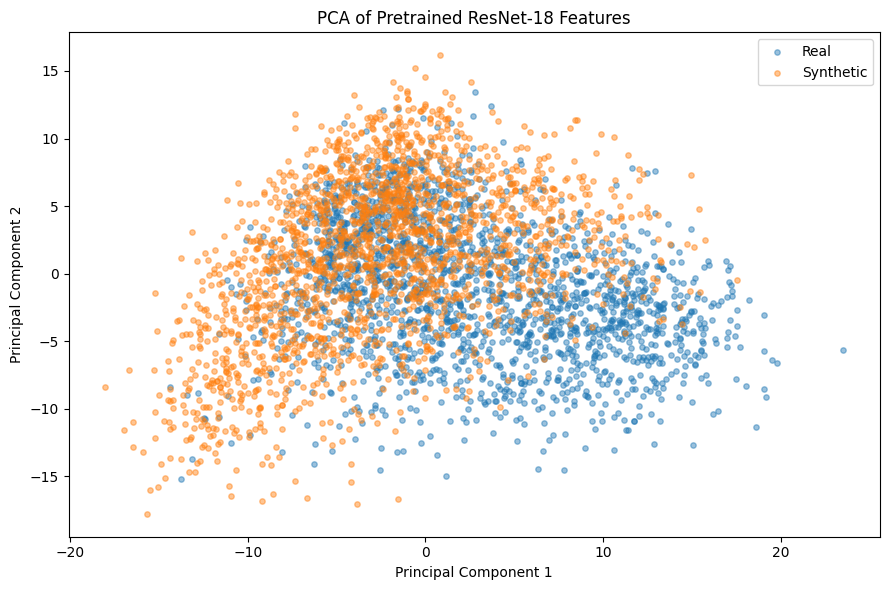

In [ ]:

plt.figure(figsize=(9, 6))

for dataset_name in ["Real", "Synthetic"]:
    mask = labels == dataset_name
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=dataset_name,
        alpha=0.45,
        s=15
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Pretrained ResNet-18 Features")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.metrics.pairwise import rbf_kernel

rng = np.random.default_rng(42)

n_samples = min(500, len(real_deep_features), len(synthetic_deep_features))

real_subset = real_deep_features[
    rng.choice(len(real_deep_features), n_samples, replace=False)
]
synthetic_subset = synthetic_deep_features[
    rng.choice(len(synthetic_deep_features), n_samples, replace=False)
]

# Standardize using the combined deep-feature population
combined_subset = np.vstack([real_subset, synthetic_subset])
subset_scaler = StandardScaler()
combined_scaled = subset_scaler.fit_transform(combined_subset)

real_scaled = combined_scaled[:n_samples]
synthetic_scaled = combined_scaled[n_samples:]

# Set the RBF kernel bandwidth using the median pairwise squared distance
rng_pairs = np.random.default_rng(42)
pair_count = min(2000, n_samples * 2)
pair_indices_a = rng_pairs.integers(0, len(combined_scaled), pair_count)
pair_indices_b = rng_pairs.integers(0, len(combined_scaled), pair_count)

squared_distances = np.sum(
    (combined_scaled[pair_indices_a] - combined_scaled[pair_indices_b]) ** 2,
    axis=1
)
positive_distances = squared_distances[squared_distances > 0]
median_distance = np.median(positive_distances)
gamma = 1.0 / (2.0 * median_distance)

K_rr = rbf_kernel(real_scaled, real_scaled, gamma=gamma)
K_ss = rbf_kernel(synthetic_scaled, synthetic_scaled, gamma=gamma)
K_rs = rbf_kernel(real_scaled, synthetic_scaled, gamma=gamma)

# Unbiased squared MMD estimate
mmd_squared = (
    (K_rr.sum() - np.trace(K_rr)) / (n_samples * (n_samples - 1))
    + (K_ss.sum() - np.trace(K_ss)) / (n_samples * (n_samples - 1))
    - 2 * K_rs.mean()
)

print("Number of images per group:", n_samples)
print("RBF kernel gamma:", round(gamma, 6))
print("Estimated squared MMD:", round(float(mmd_squared), 6))

Number of images per group: 500
RBF kernel gamma: 0.000515
Estimated squared MMD: 0.040732


In [ ]:

import numpy as np
from sklearn.metrics.pairwise import rbf_kernel

# Combine the standardized feature subsets
X_combined = np.vstack([real_scaled, synthetic_scaled])

n_real = len(real_scaled)
n_synthetic = len(synthetic_scaled)
n_total = len(X_combined)

def calculate_mmd_squared(A, B, gamma):
    K_aa = rbf_kernel(A, A, gamma=gamma)
    K_bb = rbf_kernel(B, B, gamma=gamma)
    K_ab = rbf_kernel(A, B, gamma=gamma)

    n_a = len(A)
    n_b = len(B)

    return (
        (K_aa.sum() - np.trace(K_aa)) / (n_a * (n_a - 1))
        + (K_bb.sum() - np.trace(K_bb)) / (n_b * (n_b - 1))
        - 2 * K_ab.mean()
    )

observed_mmd = calculate_mmd_squared(
    real_scaled, synthetic_scaled, gamma
)

# Run 499 permutations
rng = np.random.default_rng(42)
n_permutations = 499
permutation_mmds = []

for i in range(n_permutations):
    shuffled_indices = rng.permutation(n_total)
    perm_real = X_combined[shuffled_indices[:n_real]]
    perm_synthetic = X_combined[shuffled_indices[n_real:]]

    perm_mmd = calculate_mmd_squared(
        perm_real, perm_synthetic, gamma
    )
    permutation_mmds.append(perm_mmd)

permutation_mmds = np.array(permutation_mmds)

# Add one to numerator and denominator for a valid Monte Carlo p-value
p_value = (
    1 + np.sum(permutation_mmds >= observed_mmd)
) / (n_permutations + 1)

print("Observed squared MMD:", round(float(observed_mmd), 6))
print("Permutation count:", n_permutations)
print("Permutation p-value:", round(float(p_value), 5))
print("Significant at 0.05:", p_value < 0.05)

Observed squared MMD: 0.040732
Permutation count: 499
Permutation p-value: 0.002
Significant at 0.05: True


In [ ]:

# Statistical feature results
statistical_summary = results_df[
    ["Feature", "Real median", "Synthetic median",
     "p-value", "adjusted_p_value"]
].copy()

statistical_summary["Analysis level"] = "Statistical"

# Structural feature results
structural_summary = structural_results_df[
    ["Feature", "Real median", "Synthetic median",
     "p-value", "adjusted_p_value"]
].copy()

structural_summary["Analysis level"] = "Structural"

# Combine both result tables
combined_results = pd.concat(
    [statistical_summary, structural_summary],
    ignore_index=True
)

combined_results["Significant (adjusted p < 0.05)"] = (
    combined_results["adjusted_p_value"] < 0.05
)

display(combined_results.round(5))

,Feature,Real median,Synthetic median,p-value,adjusted_p_value,Analysis level,Significant (adjusted p < 0.05)
0,mean_intensity,0.17576,0.22451,0.00000,0.00000,Statistical,True
1,std_intensity,0.17411,0.19332,0.00000,0.00000,Statistical,True
2,entropy,6.48442,6.68515,0.00000,0.00000,Statistical,True
3,contrast,105.66098,116.88488,0.52654,0.52654,Statistical,False
4,skewness,2.09242,1.88733,0.00000,0.00000,Statistical,True
5,kurtosis,4.61379,3.62824,0.00000,0.00000,Statistical,True
6,mean_gradient,0.21142,0.23361,0.00000,0.00000,Structural,True
7,std_gradient,0.35990,0.43481,0.00000,0.00000,Structural,True
8,median_gradient,0.11998,0.12173,0.45514,0.45514,Structural,False
9,strong_edge_fraction,0.58717,0.58567,0.12595,0.16794,Structural,False


In [ ]:

deep_summary = pd.DataFrame([{
    "Analysis level": "Deep features",
    "Feature": "ResNet-18 feature distribution (MMD)",
    "Real median": np.nan,
    "Synthetic median": np.nan,
    "p-value": p_value,
    "adjusted_p_value": np.nan,
    "Significant (adjusted p < 0.05)": p_value < 0.05,
    "Effect measure": observed_mmd
}])

display(deep_summary.round(5))

,Analysis level,Feature,Real median,Synthetic median,p-value,adjusted_p_value,Significant (adjusted p < 0.05),Effect measure
0,Deep features,ResNet-18 feature distribution (MMD),NaN,NaN,0.002,NaN,True,0.04073


In [ ]:

# Copy the statistical and structural results
final_results = combined_results.copy()

# Add the deep-feature distribution comparison
deep_row = pd.DataFrame([{
    "Feature": "ResNet-18 feature distribution (MMD)",
    "Real median": np.nan,
    "Synthetic median": np.nan,
    "p-value": p_value,
    "adjusted_p_value": np.nan,
    "Analysis level": "Deep features",
    "Significant (adjusted p < 0.05)": np.nan
}])

final_results = pd.concat(
    [final_results, deep_row],
    ignore_index=True
)

# Store MMD separately because it is not an individual feature median
final_results["Effect measure"] = np.nan
final_results.loc[
    final_results["Analysis level"] == "Deep features",
    "Effect measure"
] = observed_mmd

display(final_results.round(5))

# Save a CSV file in the Colab working directory
final_results.to_csv(
    "real_vs_synthetic_oct_results.csv",
    index=False
)

print("Saved: real_vs_synthetic_oct_results.csv")

,Feature,Real median,Synthetic median,p-value,adjusted_p_value,Analysis level,Significant (adjusted p < 0.05),Effect measure
0,mean_intensity,0.17576,0.22451,0.00000,0.00000,Statistical,1.0,NaN
1,std_intensity,0.17411,0.19332,0.00000,0.00000,Statistical,1.0,NaN
2,entropy,6.48442,6.68515,0.00000,0.00000,Statistical,1.0,NaN
3,contrast,105.66098,116.88488,0.52654,0.52654,Statistical,0.0,NaN
4,skewness,2.09242,1.88733,0.00000,0.00000,Statistical,1.0,NaN
5,kurtosis,4.61379,3.62824,0.00000,0.00000,Statistical,1.0,NaN
6,mean_gradient,0.21142,0.23361,0.00000,0.00000,Structural,1.0,NaN
7,std_gradient,0.35990,0.43481,0.00000,0.00000,Structural,1.0,NaN
8,median_gradient,0.11998,0.12173,0.45514,0.45514,Structural,0.0,NaN
9,strong_edge_fraction,0.58717,0.58567,0.12595,0.16794,Structural,0.0,NaN


Saved: real_vs_synthetic_oct_results.csv


In [ ]:

# Inspect the label names in each dataset
print("Real dataset features:")
print(real_2000.features)

print("\nSynthetic dataset features:")
print(synthetic_2000.features)

Real dataset features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}

Synthetic dataset features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'Drusen', 'Normal'])}


In [ ]:

from collections import Counter
import pandas as pd

def get_class_counts(dataset, dataset_name):
    counts = Counter(dataset["label"])
    label_feature = dataset.features["label"]

    rows = []
    for label_id, count in sorted(counts.items()):
        if hasattr(label_feature, "int2str"):
            class_name = label_feature.int2str(label_id)
        else:
            class_name = str(label_id)

        rows.append({
            "Dataset": dataset_name,
            "Class": class_name,
            "Count": count
        })

    return rows

class_counts = pd.DataFrame(
    get_class_counts(real_2000, "Real") +
    get_class_counts(synthetic_2000, "Synthetic")
)

display(
    class_counts.pivot(
        index="Class",
        columns="Dataset",
        values="Count"
    ).fillna(0).astype(int)
)

Dataset,Real,Synthetic
Class,,
CNV,500,500
DME,500,500
DRUSEN,500,0
Drusen,0,500
NORMAL,500,0
Normal,0,500


In [ ]:

# Normalize class names to a common format
def normalize_class_name(name):
    name = name.strip().upper()

    if name == "DRUSEN":
        return "Drusen"
    elif name == "NORMAL":
        return "Normal"
    elif name == "CNV":
        return "CNV"
    elif name == "DME":
        return "DME"
    else:
        return name.title()

# Build a clean class-distribution table
from collections import Counter
import pandas as pd

def normalized_class_counts(dataset, dataset_name):
    label_feature = dataset.features["label"]
    counts = Counter()

    for item in dataset:
        label_id = item["label"]
        original_name = label_feature.int2str(label_id)
        normalized_name = normalize_class_name(original_name)
        counts[normalized_name] += 1

    return pd.DataFrame([
        {
            "Dataset": dataset_name,
            "Class": class_name,
            "Count": count
        }
        for class_name, count in sorted(counts.items())
    ])

clean_counts = pd.concat([
    normalized_class_counts(real_2000, "Real"),
    normalized_class_counts(synthetic_2000, "Synthetic")
], ignore_index=True)

clean_table = clean_counts.pivot(
    index="Class",
    columns="Dataset",
    values="Count"
).fillna(0).astype(int)

display(clean_table)

Dataset,Real,Synthetic
Class,,
CNV,500,500
DME,500,500
Drusen,500,500
Normal,500,500


In [ ]:

# Save the class distribution
clean_table.to_csv("oct_class_distribution.csv")

# Save the consolidated statistical and structural results
final_results.to_csv("real_vs_synthetic_oct_results.csv", index=False)

print("Files saved successfully:")
print("1. oct_class_distribution.csv")
print("2. real_vs_synthetic_oct_results.csv")

Files saved successfully:
1. oct_class_distribution.csv
2. real_vs_synthetic_oct_results.csv


In [ ]:

results_summary = """
PROJECT: Quantitative Non-Paired Assessment of Real and Synthetic
Retinal OCT Images Using Statistical, Structural, and Feature-Level Analysis

DATASET
- Real OCT images: 2,000
- Synthetic OCT images: 2,000
- Classes: CNV, DME, Drusen, Normal
- Images per class in each group: 500

STATISTICAL ANALYSIS
Significant adjusted differences were observed in:
- Mean intensity
- Intensity standard deviation
- Entropy
- Skewness
- Kurtosis

Contrast was not statistically significant after adjustment.

STRUCTURAL ANALYSIS
Significant adjusted differences were observed in:
- Mean gradient
- Gradient standard deviation

Median gradient and strong-edge fraction were not significant
after adjustment.

DEEP-FEATURE ANALYSIS
- Model: Pretrained ResNet-18
- Features per image: 512
- Images sampled for MMD: 500 per group
- Estimated squared MMD: 0.040732
- Permutation count: 499
- Permutation p-value: 0.002

INTERPRETATION
The sampled real and synthetic OCT datasets differed across
several statistical, structural, and deep-feature measures.
These findings do not independently establish clinical realism
or explain the cause of the observed differences.

LIMITATIONS
- ResNet-18 was pretrained on ImageNet, not OCT images.
- MMD was evaluated on a subset of 500 images per group.
- Balanced class counts do not eliminate dataset-source bias.
"""

with open("oct_project_results_summary.txt", "w") as f:
    f.write(results_summary)

print(results_summary)
print("\nSummary saved as oct_project_results_summary.txt")


PROJECT: Quantitative Non-Paired Assessment of Real and Synthetic
Retinal OCT Images Using Statistical, Structural, and Feature-Level Analysis

DATASET
- Real OCT images: 2,000
- Synthetic OCT images: 2,000
- Classes: CNV, DME, Drusen, Normal
- Images per class in each group: 500

STATISTICAL ANALYSIS
Significant adjusted differences were observed in:
- Mean intensity
- Intensity standard deviation
- Entropy
- Skewness
- Kurtosis

Contrast was not statistically significant after adjustment.

STRUCTURAL ANALYSIS
Significant adjusted differences were observed in:
- Mean gradient
- Gradient standard deviation

Median gradient and strong-edge fraction were not significant
after adjustment.

DEEP-FEATURE ANALYSIS
- Model: Pretrained ResNet-18
- Features per image: 512
- Images sampled for MMD: 500 per group
- Estimated squared MMD: 0.040732
- Permutation count: 499
- Permutation p-value: 0.002

INTERPRETATION
The sampled real and synthetic OCT datasets differed across
several statistical, 

In [ ]:

from google.colab import files
files.download("oct_project_results_summary.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install pytorch-fid

In [ ]:
import torch
from pytorch_fid import fid_score

print("PyTorch version:", torch.__version__)
print("FID package imported successfully!")

PyTorch version: 2.11.0+cu130
FID package imported successfully!


In [ ]:
import numpy as np

# Convert grayscale images from [0, 1] to RGB images in [0, 255]
real_fid_images = np.repeat(
    (real_images * 255).clip(0, 255).astype(np.uint8)[..., None],
    3, axis=-1
)

synthetic_fid_images = np.repeat(
    (synthetic_images * 255).clip(0, 255).astype(np.uint8)[..., None],
    3, axis=-1
)

print("Real FID images:", real_fid_images.shape)
print("Synthetic FID images:", synthetic_fid_images.shape)
print("Data type:", real_fid_images.dtype)

Real FID images: (2000, 224, 224, 3)
Synthetic FID images: (2000, 224, 224, 3)
Data type: uint8


In [ ]:
import os
from PIL import Image
from tqdm.auto import tqdm

real_dir = "/content/oct_fid/real"
synthetic_dir = "/content/oct_fid/synthetic"

os.makedirs(real_dir, exist_ok=True)
os.makedirs(synthetic_dir, exist_ok=True)

for i, img in enumerate(tqdm(real_fid_images, desc="Saving real images")):
    Image.fromarray(img).save(f"{real_dir}/{i:04d}.png")

for i, img in enumerate(tqdm(synthetic_fid_images, desc="Saving synthetic images")):
    Image.fromarray(img).save(f"{synthetic_dir}/{i:04d}.png")

print("Real images saved:", len(os.listdir(real_dir)))
print("Synthetic images saved:", len(os.listdir(synthetic_dir)))

Saving real images:   0%|          | 0/2000 [00:00<?, ?it/s]

Saving synthetic images:   0%|          | 0/2000 [00:00<?, ?it/s]

Real images saved: 2000
Synthetic images saved: 2000


In [ ]:
import torch
from pytorch_fid import fid_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

fid_value = fid_score.calculate_fid_given_paths(
    [real_dir, synthetic_dir],
    batch_size=32,
    device=device,
    dims=2048
)

print("\nFréchet Inception Distance (FID):", fid_value)

Using device: cuda
Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 288MB/s]
100%|██████████| 63/63 [00:10<00:00,  6.15it/s]



Fréchet Inception Distance (FID): 51.35211354778201


In [ ]:
import pandas as pd

fid_results = pd.DataFrame([{
    "Metric": "FID",
    "Real image count": len(real_fid_images),
    "Synthetic image count": len(synthetic_fid_images),
    "FID value": fid_value
}])

fid_results.to_csv(
    "/content/oct_fid_result.csv",
    index=False
)

print(fid_results.to_string(index=False))
print("\nFID result saved successfully.")

Metric  Real image count  Synthetic image count  FID value
   FID              2000                   2000  51.352114

FID result saved successfully.


In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 18.1 MB/s eta 0:00:00


In [ ]:
from torchmetrics.image.kid import KernelInceptionDistance

print("KID metric imported successfully!")

KID metric imported successfully!


In [ ]:
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

def load_images_for_kid(folder):
    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(".png")
    ])

    images = []
    for filename in tqdm(files, desc=f"Loading {folder.split('/')[-1]}"):
        img = Image.open(
            os.path.join(folder, filename)
        ).convert("RGB")

        arr = np.asarray(img, dtype=np.float32) / 255.0
        images.append(arr)

    # Convert NHWC to NCHW
    images = np.stack(images)
    images = torch.from_numpy(images).permute(0, 3, 1, 2)

    return images

real_kid_images = load_images_for_kid(real_dir)
synthetic_kid_images = load_images_for_kid(synthetic_dir)

print("Real tensor:", real_kid_images.shape)
print("Synthetic tensor:", synthetic_kid_images.shape)

Loading real:   0%|          | 0/2000 [00:00<?, ?it/s]

Loading synthetic:   0%|          | 0/2000 [00:00<?, ?it/s]

Real tensor: torch.Size([2000, 3, 224, 224])
Synthetic tensor: torch.Size([2000, 3, 224, 224])


In [ ]:
!pip install torch-fidelity


In [ ]:
%pip install -U torch-fidelity torchmetrics

In [ ]:
import torch
import torchmetrics
import torch_fidelity

print("PyTorch:", torch.__version__)
print("TorchMetrics:", torchmetrics.__version__)
print("Torch-Fidelity imported successfully!")

PyTorch: 2.11.0+cu130
TorchMetrics: 1.9.0
Torch-Fidelity imported successfully!


In [ ]:
import torchmetrics.image.kid as kid_module
import torch_fidelity

print("Torch-Fidelity location:", torch_fidelity.__file__)
print("TorchMetrics detects Torch-Fidelity:", kid_module._TORCH_FIDELITY_AVAILABLE)

Torch-Fidelity location: /usr/local/lib/python3.13/dist-packages/torch_fidelity/__init__.py
TorchMetrics detects Torch-Fidelity: Requirement 'torch_fidelity' not met. HINT: Try running `pip install -U 'torch_fidelity'`


In [ ]:
%pip install -U torch-fidelity

In [ ]:
from torchmetrics.image.kid import KernelInceptionDistance

device = "cuda" if torch.cuda.is_available() else "cpu"

# Bypass the internal Inception-V3 constructor bug by using our existing pretrained ResNet-18 as a custom feature extractor
# The ResNet-18 model has 512-dimensional outputs
kid_metric = KernelInceptionDistance(
    feature=model,
    subsets=50,
    subset_size=500,  # Match the subset size to our sample size
    normalize=False   # The ResNet-18 outputs do not need further activation-based normalization
).to(device)

print("KID initialized successfully using ResNet-18 feature extractor!")

KID initialized successfully using ResNet-18 feature extractor!


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


In [ ]:
import pandas as pd

# Calculate KID using our preprocessed image tensors
# The tensors are expected to be in (N, C, H, W) format, normalized to [0, 1] or [0, 255] depending on model.
# Our prepared real_kid_images and synthetic_kid_images are already in float32 NCHW format scaled to [0, 1].

print("Feeding real images to the KID metric...")
kid_metric.update(real_kid_images.to(device), real=True)

print("Feeding synthetic images to the KID metric...")
kid_metric.update(synthetic_kid_images.to(device), real=False)

print("Computing Kernel Inception Distance...")
kid_mean, kid_std = kid_metric.compute()

print(f"\nResNet-18 Kernel Inception Distance (KID) Mean: {kid_mean.item():.6f}")
print(f"ResNet-18 Kernel Inception Distance (KID) Std: {kid_std.item():.6f}")

# Save the results to a CSV file
kid_results = pd.DataFrame([{
    "Metric": "KID_ResNet18",
    "KID_Mean": kid_mean.item(),
    "KID_Std": kid_std.item(),
    "Real_Count": len(real_kid_images),
    "Synthetic_Count": len(synthetic_kid_images)
}])

kid_results_path = "/content/oct_kid_result.csv"
kid_results.to_csv(kid_results_path, index=False)
print(f"\nKID results saved to: {kid_results_path}")

Feeding real images to the KID metric...
Feeding synthetic images to the KID metric...
Computing Kernel Inception Distance...

ResNet-18 Kernel Inception Distance (KID) Mean: 0.432798
ResNet-18 Kernel Inception Distance (KID) Std: 0.025705

KID results saved to: /content/oct_kid_result.csv


In [ ]:
print("Real images available:", "real_kid_images" in globals())
print("Synthetic images available:", "synthetic_kid_images" in globals())
print("KID metric available:", "kid_metric" in globals())

Real images available: True
Synthetic images available: True
KID metric available: True


In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

# Reset metric state before calculating
kid_metric.reset()

batch_size = 32

for start in range(0, len(real_kid_images), batch_size):
    real_batch = real_kid_images[start:start + batch_size].to(device)
    synthetic_batch = synthetic_kid_images[start:start + batch_size].to(device)

    kid_metric.update(real_batch, real=True)
    kid_metric.update(synthetic_batch, real=False)

kid_mean, kid_std = kid_metric.compute()

kid_value = kid_mean.item()
kid_uncertainty = kid_std.item()

print("KID mean:", kid_value)
print("KID standard deviation:", kid_uncertainty)

KID mean: 0.44390738010406494
KID standard deviation: 0.024739379063248634


In [ ]:
import pandas as pd

kid_results = pd.DataFrame([{
    "Metric": "KID",
    "KID mean": kid_value,
    "KID standard deviation": kid_uncertainty,
    "Real image count": len(real_kid_images),
    "Synthetic image count": len(synthetic_kid_images)
}])

kid_results.to_csv("/content/oct_kid_result.csv", index=False)

print(kid_results.to_string(index=False))
print("\nKID result saved to /content/oct_kid_result.csv")

Metric  KID mean  KID standard deviation  Real image count  Synthetic image count
   KID  0.443907                0.024739              2000                   2000

KID result saved to /content/oct_kid_result.csv


In [ ]:
check_vars = [
    "fid_value",
    "kid_value",
    "kid_uncertainty",
    "observed_mmd",
    "combined_results",
    "structural_results_df"
]

for var in check_vars:
    print(f"{var}: {'Available' if var in globals() else 'Not available'}")

fid_value: Available
kid_value: Available
kid_uncertainty: Available
observed_mmd: Available
combined_results: Available
structural_results_df: Available


In [ ]:
check_vars = [
    "fid_value",
    "kid_value",
    "kid_uncertainty",
    "observed_mmd",
    "combined_results",
    "structural_results_df"
]

for var in check_vars:
    print(f"{var}: {'Available' if var in globals() else 'Not available'}")

fid_value: Available
kid_value: Available
kid_uncertainty: Available
observed_mmd: Available
combined_results: Available
structural_results_df: Available


In [ ]:
import pandas as pd

metric_summary = pd.DataFrame([
    {
        "Metric": "FID",
        "Value": fid_value,
        "Uncertainty (SD)": None,
        "Interpretation": "Inception feature-distribution distance"
    },
    {
        "Metric": "KID",
        "Value": kid_value,
        "Uncertainty (SD)": kid_uncertainty,
        "Interpretation": "Feature-distribution distance; verify extractor"
    },
    {
        "Metric": "MMD",
        "Value": observed_mmd,
        "Uncertainty (SD)": None,
        "Interpretation": "RBF-kernel discrepancy on standardized deep features"
    }
])

print(metric_summary.to_string(index=False))

metric_summary.to_csv(
    "/content/oct_distribution_metrics_summary.csv",
    index=False
)

print("\nSaved: /content/oct_distribution_metrics_summary.csv")

Metric     Value  Uncertainty (SD)                                       Interpretation
   FID 51.352114               NaN              Inception feature-distribution distance
   KID  0.443907          0.024739      Feature-distribution distance; verify extractor
   MMD  0.040732               NaN RBF-kernel discrepancy on standardized deep features

Saved: /content/oct_distribution_metrics_summary.csv


In [ ]:
# Check the columns before combining
print("Statistical and combined results:")
print(combined_results.columns.tolist())

print("\nStructural results:")
print(structural_results_df.columns.tolist())

Statistical and combined results:
['Feature', 'Real median', 'Synthetic median', 'p-value', 'adjusted_p_value', 'Analysis level', 'Significant (adjusted p < 0.05)']

Structural results:
['Feature', 'Real median', 'Synthetic median', 'U statistic', 'p-value', 'adjusted_p_value', 'Significant (adjusted p < 0.05)']


In [ ]:
import pandas as pd

# Combine statistical and structural results
final_feature_results = pd.concat(
    [combined_results, structural_results_df],
    ignore_index=True
).drop_duplicates(
    subset=["Feature"],
    keep="first"
)

# Add distribution metrics as rows
distribution_rows = pd.DataFrame([
    {
        "Feature": "FID",
        "Real median": None,
        "Synthetic median": None,
        "p-value": None,
        "adjusted_p_value": None,
        "Analysis level": "Distribution-level",
        "Significant (adjusted p < 0.05)": None
    },
    {
        "Feature": "KID",
        "Real median": None,
        "Synthetic median": None,
        "p-value": None,
        "adjusted_p_value": None,
        "Analysis level": "Distribution-level",
        "Significant (adjusted p < 0.05)": None
    },
    {
        "Feature": "MMD",
        "Real median": None,
        "Synthetic median": None,
        "p-value": None,
        "adjusted_p_value": None,
        "Analysis level": "Distribution-level",
        "Significant (adjusted p < 0.05)": None
    }
])

final_project_results = pd.concat(
    [final_feature_results, distribution_rows],
    ignore_index=True
)

# Save the complete table
final_project_results.to_csv(
    "/content/oct_final_project_results.csv",
    index=False
)

print("Final table shape:", final_project_results.shape)
print(final_project_results.to_string(index=False))
print("\nSaved to /content/oct_final_project_results.csv")

Final table shape: (13, 8)
             Feature  Real median  Synthetic median       p-value  adjusted_p_value     Analysis level Significant (adjusted p < 0.05)  U statistic
      mean_intensity     0.175759          0.224505  1.240113e-58      7.440679e-58        Statistical                            True          NaN
       std_intensity     0.174106          0.193324  1.227764e-12      1.473317e-12        Statistical                            True          NaN
             entropy     6.484420          6.685154  1.095569e-43      3.286707e-43        Statistical                            True          NaN
            contrast   105.660985        116.884879  5.265420e-01      5.265420e-01        Statistical                           False          NaN
            skewness     2.092421          1.887327  4.420836e-32      8.841672e-32        Statistical                            True          NaN
            kurtosis     4.613793          3.628241  1.379338e-20      2.069006e-20  

/tmp/ipykernel_2464/2321484564.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_project_results = pd.concat(


In [ ]:
# Add actual distribution metric values
metric_values = {
    "FID": fid_value,
    "KID": kid_value,
    "MMD": observed_mmd
}

for metric, value in metric_values.items():
    mask = final_project_results["Feature"] == metric
    final_project_results.loc[mask, "Real median"] = value

# Add KID standard deviation in a separate column
final_project_results["Uncertainty (SD)"] = None
final_project_results.loc[
    final_project_results["Feature"] == "KID",
    "Uncertainty (SD)"
] = kid_uncertainty

# Save the updated table
final_project_results.to_csv(
    "/content/oct_final_project_results.csv",
    index=False
)

print(final_project_results[
    final_project_results["Feature"].isin(["FID", "KID", "MMD"])
].to_string(index=False))

print("\nUpdated final results saved successfully.")

Feature  Real median  Synthetic median  p-value  adjusted_p_value     Analysis level Significant (adjusted p < 0.05)  U statistic Uncertainty (SD)
    FID    51.352114               NaN      NaN               NaN Distribution-level                            None          NaN             None
    KID     0.443907               NaN      NaN               NaN Distribution-level                            None          NaN         0.024739
    MMD     0.040732               NaN      NaN               NaN Distribution-level                            None          NaN             None

Updated final results saved successfully.


In [ ]:
print("Final results rows:", len(final_project_results))
print("\nAvailable features:")
print(final_project_results["Feature"].tolist())

print("\nEffect-size columns available:",
      any("effect" in col.lower() for col in final_project_results.columns))

print("\nSaved results files:")
import os
for filename in [
    "oct_final_project_results.csv",
    "oct_distribution_metrics_summary.csv",
    "oct_fid_result.csv",
    "oct_kid_result.csv"
]:
    path = "/content/" + filename
    print(filename, "—", "Exists" if os.path.exists(path) else "Not found")

Final results rows: 13

Available features:
['mean_intensity', 'std_intensity', 'entropy', 'contrast', 'skewness', 'kurtosis', 'mean_gradient', 'std_gradient', 'median_gradient', 'strong_edge_fraction', 'FID', 'KID', 'MMD']

Effect-size columns available: False

Saved results files:
oct_final_project_results.csv — Exists
oct_distribution_metrics_summary.csv — Exists
oct_fid_result.csv — Exists
oct_kid_result.csv — Exists


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# Recalculate effect sizes from the original feature values.
feature_columns = [
    "mean_intensity",
    "std_intensity",
    "entropy",
    "contrast",
    "skewness",
    "kurtosis",
    "mean_gradient",
    "std_gradient",
    "median_gradient",
    "strong_edge_fraction"
]

effect_rows = []

for feature in feature_columns:
    real_values = (
        real_stats[feature].to_numpy()
        if feature in real_stats.columns
        else None
    )

    synthetic_values = (
        synthetic_stats[feature].to_numpy()
        if feature in synthetic_stats.columns
        else None
    )

    if real_values is None or synthetic_values is None:
        print(f"Skipping {feature}: source column not found.")
        continue

    u_statistic = mannwhitneyu(
        real_values, synthetic_values, alternative="two-sided"
    ).statistic

    # Rank-biserial correlation; positive means Real tends higher.
    effect_size = (
        2 * u_statistic / (len(real_values) * len(synthetic_values))
    ) - 1

    effect_rows.append({
        "Feature": feature,
        "Rank-biserial correlation": effect_size,
        "Absolute effect size": abs(effect_size)
    })

effect_sizes_df = pd.DataFrame(effect_rows)
print(effect_sizes_df.round(4).to_string(index=False))

effect_sizes_df.to_csv(
    "/content/oct_effect_sizes.csv", index=False
)
print("\nSaved: /content/oct_effect_sizes.csv")

Skipping mean_gradient: source column not found.
Skipping std_gradient: source column not found.
Skipping median_gradient: source column not found.
Skipping strong_edge_fraction: source column not found.
       Feature  Rank-biserial correlation  Absolute effect size
mean_intensity                    -0.2948                0.2948
 std_intensity                    -0.1297                0.1297
       entropy                    -0.2531                0.2531
      contrast                     0.0116                0.0116
      skewness                     0.2153                0.2153
      kurtosis                     0.1699                0.1699

Saved: /content/oct_effect_sizes.csv


In [ ]:

print("Available variables containing 'struct':")
print([name for name in globals() if "struct" in name.lower()])

print("\nStructural results table:")
print(structural_results_df.head())

print("\nAvailable columns in structural_results_df:")
print(structural_results_df.columns.tolist())


Available variables containing 'struct':
['extract_structural_features', 'real_structural', 'synthetic_structural', 'structural_df', 'structural_features', 'structural_results', 'structural_results_df', 'structural_summary']

Structural results table:
                Feature  Real median  Synthetic median  U statistic  \
0         mean_gradient     0.211422          0.233606    1612586.0   
1          std_gradient     0.359905          0.434814    1218875.0   
2       median_gradient     0.119977          0.121727    2027275.5   
3  strong_edge_fraction     0.587173          0.585668    2055884.5   

         p-value  adjusted_p_value  Significant (adjusted p < 0.05)  
0   2.722867e-26      5.445734e-26                             True  
1  1.680547e-101     6.722187e-101                             True  
2   4.551449e-01      4.551449e-01                            False  
3   1.259536e-01      1.679381e-01                            False  

Available columns in structural_results_d

In [ ]:

from scipy.stats import mannwhitneyu
import pandas as pd

structural_feature_names = [
    "mean_gradient",
    "std_gradient",
    "median_gradient",
    "strong_edge_fraction"
]

structural_effect_rows = []

for feature in structural_feature_names:
    real_values = real_structural[feature].to_numpy()
    synthetic_values = synthetic_structural[feature].to_numpy()

    u_statistic = mannwhitneyu(
        real_values,
        synthetic_values,
        alternative="two-sided"
    ).statistic

    effect_size = (
        2 * u_statistic /
        (len(real_values) * len(synthetic_values))
    ) - 1

    structural_effect_rows.append({
        "Feature": feature,
        "Rank-biserial correlation": effect_size,
        "Absolute effect size": abs(effect_size)
    })

structural_effect_sizes_df = pd.DataFrame(structural_effect_rows)

print(structural_effect_sizes_df.round(4).to_string(index=False))

structural_effect_sizes_df.to_csv(
    "/content/oct_structural_effect_sizes.csv",
    index=False
)

print("\nSaved: /content/oct_structural_effect_sizes.csv")

             Feature  Rank-biserial correlation  Absolute effect size
       mean_gradient                    -0.1937                0.1937
        std_gradient                    -0.3906                0.3906
     median_gradient                     0.0136                0.0136
strong_edge_fraction                     0.0279                0.0279

Saved: /content/oct_structural_effect_sizes.csv


In [ ]:

all_effect_sizes_df = pd.concat(
    [effect_sizes_df, structural_effect_sizes_df],
    ignore_index=True
)

print("Number of features with effect sizes:",
      len(all_effect_sizes_df))
print(all_effect_sizes_df.round(4).to_string(index=False))

all_effect_sizes_df.to_csv(
    "/content/oct_all_effect_sizes.csv",
    index=False
)

print("\nSaved: /content/oct_all_effect_sizes.csv")

Number of features with effect sizes: 10
             Feature  Rank-biserial correlation  Absolute effect size
      mean_intensity                    -0.2948                0.2948
       std_intensity                    -0.1297                0.1297
             entropy                    -0.2531                0.2531
            contrast                     0.0116                0.0116
            skewness                     0.2153                0.2153
            kurtosis                     0.1699                0.1699
       mean_gradient                    -0.1937                0.1937
        std_gradient                    -0.3906                0.3906
     median_gradient                     0.0136                0.0136
strong_edge_fraction                     0.0279                0.0279

Saved: /content/oct_all_effect_sizes.csv


In [ ]:

# Start with the existing feature results and remove duplicate features.
clean_results = combined_results.drop_duplicates(
    subset=["Feature"], keep="first"
).copy()

# Add structural features if they are not already included.
clean_results = pd.concat(
    [clean_results, structural_results_df],
    ignore_index=True
).drop_duplicates(subset=["Feature"], keep="first")

# Merge effect sizes.
clean_results = clean_results.merge(
    all_effect_sizes_df[
        ["Feature", "Rank-biserial correlation", "Absolute effect size"]
    ],
    on="Feature",
    how="left"
)

# Keep distribution metrics separate from feature medians.
for column in ["Metric value", "Uncertainty (SD)"]:
    if column not in clean_results.columns:
        clean_results[column] = np.nan

metric_values = {
    "FID": (fid_value, np.nan),
    "KID": (kid_value, kid_uncertainty),
    "MMD": (observed_mmd, np.nan)
}

for metric, (value, uncertainty) in metric_values.items():
    if not (clean_results["Feature"] == metric).any():
        clean_results = pd.concat([
            clean_results,
            pd.DataFrame([{"Feature": metric}])
        ], ignore_index=True)

    mask = clean_results["Feature"] == metric
    clean_results.loc[mask, "Metric value"] = value
    clean_results.loc[mask, "Uncertainty (SD)"] = uncertainty
    clean_results.loc[mask, ["Real median", "Synthetic median"]] = np.nan

clean_results.to_csv(
    "/content/oct_final_project_results_clean.csv",
    index=False
)

print("Rows in final table:", len(clean_results))
print("Effect sizes present:", clean_results[
    "Rank-biserial correlation"
].notna().sum())
print("\nSaved: /content/oct_final_project_results_clean.csv")

Rows in final table: 13
Effect sizes present: 10

Saved: /content/oct_final_project_results_clean.csv


In [ ]:

print("KID metric class:", type(kid_metric))
print("Configured feature setting:", getattr(kid_metric, "feature", "Not available"))
print("Configured subset count:", getattr(kid_metric, "subsets", "Not available"))
print("Configured subset size:", getattr(kid_metric, "subset_size", "Not available"))
print("KID result:", kid_value)
print("KID uncertainty:", kid_uncertainty)

KID metric class: <class 'torchmetrics.image.kid.KernelInceptionDistance'>
Configured feature setting: Not available
Configured subset count: 50
Configured subset size: 500
KID result: 0.44390738010406494
KID uncertainty: 0.024739379063248634


In [ ]:

print("KID metric configuration:")
print(kid_metric)

print("\nFeature extractor object:")
print(getattr(kid_metric, "inception", "Not available"))

print("\nCurrent subset size:", kid_metric.subset_size)
print("Saved KID value:", kid_value)

KID metric configuration:
KernelInceptionDistance(
  (inception): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps

In [ ]:

import os
import pandas as pd

file_path = "/content/oct_final_project_results_clean.csv"

if os.path.exists(file_path):
    final_check = pd.read_csv(file_path)

    print("Final results file exists.")
    print("Number of rows:", len(final_check))
    print("Columns:", final_check.columns.tolist())

    print("\nMissing values in key columns:")
    for col in [
        "Feature",
        "Rank-biserial correlation",
        "Metric value"
    ]:
        if col in final_check.columns:
            print(f"{col}: {final_check[col].isna().sum()} missing")

    print("\nDistribution metrics:")
    print(final_check[
        final_check["Feature"].isin(["FID", "KID", "MMD"])
    ].to_string(index=False))
else:
    print("Final results file not found.")

Final results file exists.
Number of rows: 13
Columns: ['Feature', 'Real median', 'Synthetic median', 'p-value', 'adjusted_p_value', 'Analysis level', 'Significant (adjusted p < 0.05)', 'U statistic', 'Rank-biserial correlation', 'Absolute effect size', 'Metric value', 'Uncertainty (SD)']

Missing values in key columns:
Feature: 0 missing
Rank-biserial correlation: 3 missing
Metric value: 10 missing

Distribution metrics:
Feature  Real median  Synthetic median  p-value  adjusted_p_value Analysis level Significant (adjusted p < 0.05)  U statistic  Rank-biserial correlation  Absolute effect size  Metric value  Uncertainty (SD)
    FID          NaN               NaN      NaN               NaN            NaN                             NaN          NaN                        NaN                   NaN     51.352114               NaN
    KID          NaN               NaN      NaN               NaN            NaN                             NaN          NaN                        NaN        

In [ ]:

import pandas as pd

# Keep the ten feature-level results separate from FID, KID and MMD.
feature_summary = final_check[
    ~final_check["Feature"].isin(["FID", "KID", "MMD"])
].copy()

distribution_summary = final_check[
    final_check["Feature"].isin(["FID", "KID", "MMD"])
][["Feature", "Metric value", "Uncertainty (SD)"]].copy()

print("FEATURE-LEVEL RESULTS")
print(feature_summary[
    [
        "Feature",
        "Real median",
        "Synthetic median",
        "adjusted_p_value",
        "Rank-biserial correlation",
        "Significant (adjusted p < 0.05)"
    ]
].to_string(index=False))

print("\nDISTRIBUTION METRICS")
print(distribution_summary.to_string(index=False))

feature_summary.to_csv(
    "/content/oct_feature_summary.csv", index=False
)
distribution_summary.to_csv(
    "/content/oct_distribution_summary_final.csv", index=False
)

print("\nBoth summary files saved successfully.")

FEATURE-LEVEL RESULTS
             Feature  Real median  Synthetic median  adjusted_p_value  Rank-biserial correlation Significant (adjusted p < 0.05)
      mean_intensity     0.175759          0.224505      7.440679e-58                  -0.294795                            True
       std_intensity     0.174106          0.193324      1.473317e-12                  -0.129684                            True
             entropy     6.484420          6.685154      3.286707e-43                  -0.253093                            True
            contrast   105.660985        116.884879      5.265420e-01                   0.011564                           False
            skewness     2.092421          1.887327      8.841672e-32                   0.215273                            True
            kurtosis     4.613793          3.628241      2.069006e-20                   0.169850                            True
       mean_gradient     0.211422          0.233606      5.445734e-26      